# **Seizure prediction using Multi Scale Temporal Model and Synchronization based Attention Mechanism**

In [ ]:
!pip install tensorflow numpy pandas scikit-learn matplotlib seaborn opencv-python pillow


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
data_directory = '/content/train.csv'

In [13]:
import os
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder

def load_eeg_spectrograms(csv_path, spectrogram_columns, label_column):
    # Load the SINGLE CSV file
    df = pd.read_csv(csv_path)

    # Extract spectrogram values
    spectrogram_data = df[spectrogram_columns].values

    # Extract labels
    label_data = df[label_column].values

    # Convert spectrograms into numpy array
    spectrograms = np.array(spectrogram_data)

    # Encode labels
    label_encoder = LabelEncoder()
    labels = label_encoder.fit_transform(label_data)

    return spectrograms, labels


# ====== Your Paths and Columns ======

csv_path = '/content/train.csv'

spectrogram_columns = [
    'spectrogram_id', 'spectrogram_sub_id', 'spectrogram_label_offset_seconds',
    'label_id', 'patient_id', 'expert_consensus', 'seizure_vote', 'lpd_vote',
    'gpd_vote', 'lrda_vote', 'grda_vote', 'other_vote', 'fold'
]

label_column = 'expert_consensus'

# ===== Load the data =====
spectrograms, labels = load_eeg_spectrograms(csv_path, spectrogram_columns, label_column)

print("Spectrograms shape:", spectrograms.shape)
print("Labels shape:", labels.shape)


Spectrograms shape: (11138, 13)
Labels shape: (11138,)


In [14]:
file_path = '/content/train.csv'

In [15]:
!ls -l /content/train.csv

-rw-r--r-- 1 root root 1054466 Nov 20 09:05 /content/train.csv


In [16]:
# Import Necessary Libraries
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
import tensorflow as tf

# Step 1: Verify the File Path
#file_path = '/content/drive/MyDrive/train.csv'

# Check if the path is a file
if os.path.isfile(file_path):
    print("File found. Proceeding with data loading...")
else:
    print("File not found. Check the file path.")
    # List contents in the directory to help identify the file
    !ls /content/train.csv

# Step 2: Load the EEG Spectrogram CSV File
df = pd.read_csv(file_path)

# Inspect the Data
print("\nFirst 5 rows of the dataset:")
print(df.head())
print("\nDataset Information:")
print(df.info())

# Step 3: Drop Non-Numeric Columns
numeric_df = df.select_dtypes(include=[np.number])

# Extract Spectrograms and Labels
spectrograms = numeric_df.drop(columns=['label_id']).values  # Drop the label column if present
labels = df['expert_consensus'].values  # Assuming 'expert_consensus' is the target label

# Step 4: Convert Labels to Numeric
label_encoder = LabelEncoder()
labels = label_encoder.fit_transform(labels)
labels = tf.keras.utils.to_categorical(labels)

# Step 5: Normalize the Spectrogram Data
scaler = StandardScaler()
scaled_spectrograms = scaler.fit_transform(spectrograms)

# Step 6: Reshape for CNN Input
nsamples, nfeatures = scaled_spectrograms.shape
img_size = int(np.sqrt(nfeatures))
if img_size * img_size == nfeatures:  # Check if it's a perfect square
    scaled_spectrograms = scaled_spectrograms.reshape((nsamples, img_size, img_size, 1))

# Step 7: Split Data
X_train, X_test, y_train, y_test = train_test_split(scaled_spectrograms, labels, test_size=0.2, random_state=42)

# Display Data Shapes
print('\nTraining data shape:', X_train.shape)
print('Test data shape:', X_test.shape)
print('Training labels shape:', y_train.shape)
print('Test labels shape:', y_test.shape)


File found. Proceeding with data loading...

First 5 rows of the dataset:
       eeg_id  eeg_sub_id  eeg_label_offset_seconds  spectrogram_id  \
0  1628180742           0                       0.0          353733   
1  2277392603           0                       0.0          924234   
2   722738444           0                       0.0          999431   
3   387987538           0                       0.0         1084844   
4  2175806584           0                       0.0         1219001   

   spectrogram_sub_id  spectrogram_label_offset_seconds    label_id  \
0                   0                               0.0   127492639   
1                   0                               0.0  1978807404   
2                   0                               0.0   557980729   
3                   0                               0.0  4099147263   
4                   0                               0.0  1963161945   

   patient_id expert_consensus  seizure_vote  lpd_vote  gpd_vote  lrda_v

# **Code for MSTM Model with TCN-1D Dilation conv**

In [17]:
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, accuracy_score
import numpy as np  # Make sure numpy is imported

def create_tcn_mstm_model(input_shape, num_classes):
    inputs = layers.Input(shape=input_shape)

    # TCN-style Multi-Scale Temporal Convolutions (with dilation and causal padding)
    conv1 = layers.Conv1D(64, kernel_size=3, dilation_rate=1, activation='relu', padding='causal')(inputs)
    conv2 = layers.Conv1D(64, kernel_size=5, dilation_rate=2, activation='relu', padding='causal')(inputs)
    conv3 = layers.Conv1D(64, kernel_size=7, dilation_rate=4, activation='relu', padding='causal')(inputs)

    # Concatenate multi-scale features
    concatenated = layers.concatenate([conv1, conv2, conv3])
    pooled = layers.GlobalAveragePooling1D()(concatenated)

    # Fully connected layers
    dense = layers.Dense(128, activation='relu')(pooled)
    dropout = layers.Dropout(0.5)(dense)
    outputs = layers.Dense(num_classes, activation='softmax')(dropout)

    model = models.Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

    return model

# Reshape the input to add an extra dimension for Conv1D
X_train = np.expand_dims(X_train, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

input_shape = X_train.shape[1:]  # Should be (timesteps, 1)
num_classes = y_train.shape[1]

# Create and compile the TCN-style MSTM model
tcn_mstm_model = create_tcn_mstm_model(input_shape, num_classes)
tcn_mstm_model.summary()

# Train the model
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
history = tcn_mstm_model.fit(X_train, y_train,
                             validation_data=(X_test, y_test),
                             epochs=50,
                             batch_size=32,
                             callbacks=[early_stop])

# Evaluate the model
y_pred = tcn_mstm_model.predict(X_test)
y_pred_classes = y_pred.argmax(axis=1)
y_true = y_test.argmax(axis=1)

print("TCN-MSTM Model Accuracy:", accuracy_score(y_true, y_pred_classes))
print(classification_report(y_true, y_pred_classes))


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 14, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 14, 64)    │        256 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 14, 64)    │        384 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 14, 64)    │        512 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 14, 192)   │          0 │ conv1d[0][0],     │
│ (Concatenate)       │                   │            │ conv1d_1[0][0],   │
│                     │                   │            │ conv1d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 192)       │          0 │ concatenate[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     24,704 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 6)         │        774 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 26,630 (104.02 KB)

 Trainable params: 26,630 (104.02 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.4325 - loss: 1.5272 - val_accuracy: 0.6598 - val_loss: 0.8277
Epoch 2/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7273 - loss: 0.7587 - val_accuracy: 0.8469 - val_loss: 0.4648
Epoch 3/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8046 - loss: 0.4850 - val_accuracy: 0.8411 - val_loss: 0.3756
Epoch 4/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.8385 - loss: 0.3965 - val_accuracy: 0.8384 - val_loss: 0.3320
Epoch 5/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8435 - loss: 0.3617 - val_accuracy: 0.8860 - val_loss: 0.3019
Epoch 6/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8633 - loss: 0.3310 - val_accuracy: 0.8932 - val_loss: 0.2933
Epoch 7/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8592 - loss: 0.3311 - val_accuracy: 0.8936 - val_loss: 0.2761
Epoch 8/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8742 - loss: 0.3025 - val_accuracy: 0.

# **SBM - mutli head attention mechanism**

In [18]:
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, classification_report

def create_sync_spatial_model(input_shape, num_classes):
    inputs = layers.Input(shape=input_shape)  # shape: (time_steps, channels)

    # --- Spatial Attention using Multi-Head Attention across channels ---
    x = layers.Permute((2, 1))(inputs)  # shape becomes (channels, time_steps)

    # Optional projection to embedding space (each channel is a "token")
    x = layers.Dense(64)(x)

    # Apply Multi-Head Attention across channels
    attn_out = layers.MultiHeadAttention(num_heads=4, key_dim=32)(x, x)
    x = layers.Add()([x, attn_out])
    x = layers.LayerNormalization()(x)

    # Optionally re-permute back to (time_steps, channels)
    x = layers.Permute((2, 1))(x)  # shape back to (time_steps, features)

    # --- Temporal Encoding using Conv1D ---
    x = layers.Conv1D(64, kernel_size=3, activation='relu', padding='same')(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv1D(128, kernel_size=3, activation='relu', padding='same')(x)
    x = layers.BatchNormalization()(x)

    # Global Pooling and Dense layers
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

    return model
sync_model = create_sync_spatial_model(input_shape, num_classes)
sync_model.summary()

history_sync = sync_model.fit(X_train, y_train,
                              validation_data=(X_test, y_test),
                              epochs=50,
                              batch_size=32,
                              callbacks=[early_stop])

y_pred_sync = sync_model.predict(X_test)
y_pred_classes_sync = y_pred_sync.argmax(axis=1)

print("Synchronization Model Accuracy:", accuracy_score(y_true, y_pred_classes_sync))
print(classification_report(y_true, y_pred_classes_sync))


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 14, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute (Permute)   │ (None, 1, 14)     │          0 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1, 64)     │        960 │ permute[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 1, 64)     │     33,216 │ dense_2[0][0],    │
│ (MultiHeadAttentio… │                   │            │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 1, 64)     │          0 │ dense_2[0][0],    │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 1, 64)     │        128 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute_1 (Permute) │ (None, 64, 1)     │          0 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 64, 64)    │        256 │ permute_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64, 64)    │        256 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 64, 128)   │     24,704 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 128)   │        512 │ conv1d_4[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ batch_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 128)       │     16,512 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 6)         │        774 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 77,318 (302.02 KB)

 Trainable params: 76,934 (300.52 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 12s 27ms/step - accuracy: 0.8493 - loss: 0.5602 - val_accuracy: 0.9268 - val_loss: 0.3581
Epoch 2/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.9765 - loss: 0.0753 - val_accuracy: 0.9811 - val_loss: 0.0590
Epoch 3/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.9808 - loss: 0.0587 - val_accuracy: 0.9843 - val_loss: 0.0422
Epoch 4/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step - accuracy: 0.9849 - loss: 0.0449 - val_accuracy: 0.9794 - val_loss: 0.0531
Epoch 5/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - accuracy: 0.9798 - loss: 0.0536 - val_accuracy: 0.9798 - val_loss: 0.0516
Epoch 6/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.9873 - loss: 0.0364 - val_accuracy: 0.9811 - val_loss: 0.0464
Epoch 7/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 8s 30ms/step - accuracy: 0.9847 - loss: 0.0448 - val_accuracy: 0.9820 - val_loss: 0.0425
Epoch 8/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.9862 - loss: 0.0381 - val_ac

In [19]:
from tensorflow.keras import layers, models, Input, Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, accuracy_score
import numpy as np

# **fusion layer with SBAM spaital and MSTM-TCN**

279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
279/279 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
SBM Training Features Shape: (8910, 128)
MSTM Training Features Shape: (8910, 128)


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ SBM_Input           │ (None, 128)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 128, 1)    │          0 │ SBM_Input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_sbm (Conv1D) │ (None, 128, 64)   │        256 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 64)   │        256 │ conv1d_sbm[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ MSTM_Input          │ (None, 128)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SBM_Temporal_Attn   │ (None, 128, 64)   │          0 │ batch_normalizat… │
│ (Attention)         │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 128, 1)    │          0 │ MSTM_Input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute_2 (Permute) │ (None, 64, 128)   │          0 │ SBM_Temporal_Att… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mstcn_branch_3      │ (None, 128, 64)   │        256 │ reshape_1[0][0]   │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mstcn_branch_5      │ (None, 128, 64)   │        384 │ reshape_1[0][0]   │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mstcn_branch_7      │ (None, 128, 64)   │        512 │ reshape_1[0][0]   │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SBM_Spatial_MultiH… │ (None, 64, 128)   │     66,048 │ permute_2[0][0],  │
│ (MultiHeadAttentio… │                   │            │ permute_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mstcn_concat        │ (None, 128, 192)  │          0 │ mstcn_branch_3[0… │
│ (Concatenate)       │                   │            │ mstcn_branch_5[0… │
│                     │                   │            │ mstcn_branch_7[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute_3 (Permute) │ (None, 128, 64)   │          0 │ SBM_Spatial_Mult… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 192)  │        768 │ mstcn_concat[0][… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 128, 64)   │          0 │ permute_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 128, 192)  │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 8192)      │          0 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 24576)     │          0 │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 2,166,086 (8.26 MB)

 Trainable params: 2,165,574 (8.26 MB)

 Non-trainable params: 512 (2.00 KB)

Epoch 1/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 47s 150ms/step - accuracy: 0.9541 - loss: 0.4178 - val_accuracy: 0.9825 - val_loss: 0.2273 - learning_rate: 0.0010
Epoch 2/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 82s 151ms/step - accuracy: 0.9913 - loss: 0.1895 - val_accuracy: 0.9892 - val_loss: 0.1152 - learning_rate: 0.0010
Epoch 3/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 82s 151ms/step - accuracy: 0.9953 - loss: 0.0809 - val_accuracy: 0.9924 - val_loss: 0.0853 - learning_rate: 0.0010
Epoch 4/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 43s 155ms/step - accuracy: 0.9955 - loss: 0.0681 - val_accuracy: 0.9933 - val_loss: 0.0869 - learning_rate: 0.0010
Epoch 5/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 46s 164ms/step - accuracy: 0.9958 - loss: 0.0490 - val_accuracy: 0.9915 - val_loss: 0.0962 - learning_rate: 0.0010
Epoch 6/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 44s 158ms/step - accuracy: 0.9956 - loss: 0.0561 - val_accuracy: 0.9937 - val_loss: 0.0676 - learning_rate: 0.0010
Epoch 7/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 82s 157ms/step - accuracy: 0.9

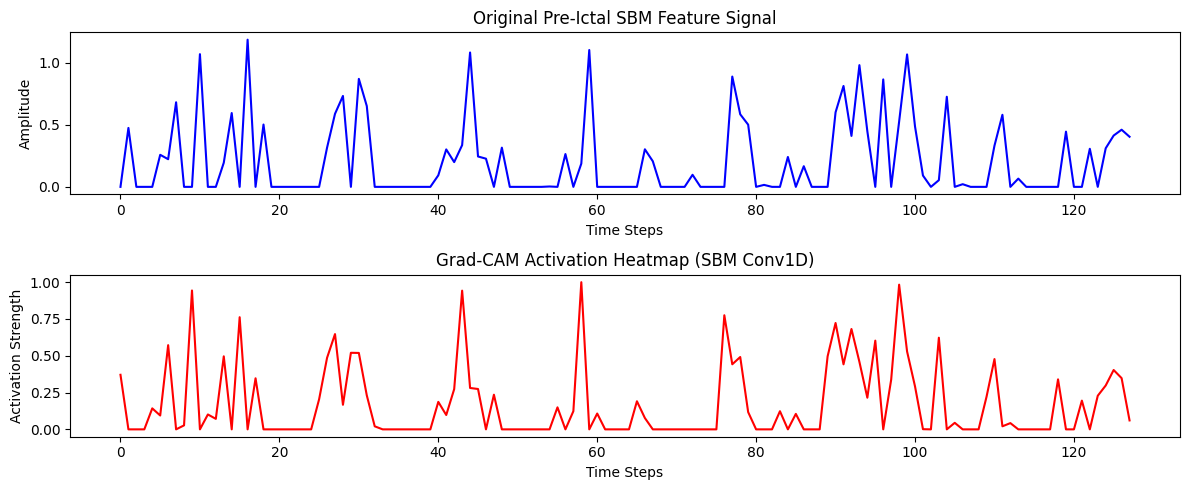

In [20]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv1D, BatchNormalization, Dropout, Flatten, Dense, Concatenate, Reshape, Attention, Permute
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

# ---------------------------------------
# STEP 1: Extract Features from Pretrained Models
# ---------------------------------------

# Assuming sync_model (SBM) and tcn_mstm_model are pretrained and available
sbm_feature_extractor = Model(inputs=sync_model.input, outputs=sync_model.layers[-2].output)
mstm_feature_extractor = Model(inputs=tcn_mstm_model.input, outputs=tcn_mstm_model.layers[-2].output)

X_train_sbm = sbm_feature_extractor.predict(X_train)
X_test_sbm = sbm_feature_extractor.predict(X_test)

X_train_mstm = mstm_feature_extractor.predict(X_train)
X_test_mstm = mstm_feature_extractor.predict(X_test)

print("SBM Training Features Shape:", X_train_sbm.shape)
print("MSTM Training Features Shape:", X_train_mstm.shape)

# ---------------------------------------
# STEP 2: Build Fusion Model with Multi-Head Attention for Spatial Attention
# ---------------------------------------

def build_fusion_model(input_shape_sbm, input_shape_mstm):
    input_sbm = Input(shape=input_shape_sbm, name="SBM_Input")
    input_mstm = Input(shape=input_shape_mstm, name="MSTM_Input")

    # --- SBM Path (Spatial + Temporal Attention) ---
    x1 = Reshape((input_shape_sbm[0], 1))(input_sbm)
    x1 = Conv1D(filters=64, kernel_size=3, activation='relu', padding="same", name="conv1d_sbm")(x1)
    x1 = BatchNormalization()(x1)

    # Temporal Attention (using standard Attention layer for simplicity)
    x1_temporal = Attention(name='SBM_Temporal_Attn')([x1, x1])

    # Spatial Attention (using Multi-Head Attention for spatial attention)
    x1_spatial = Permute((2, 1))(x1_temporal)
    x1_spatial = tf.keras.layers.MultiHeadAttention(num_heads=4, key_dim=32, name='SBM_Spatial_MultiHead_Attn')(x1_spatial, x1_spatial)
    x1_spatial = Permute((2, 1))(x1_spatial)

    x1 = Dropout(0.3)(x1_spatial)
    x1 = Flatten()(x1)

    # --- MSTM Path ---
    x2 = Reshape((input_shape_mstm[0], 1))(input_mstm)
    branch1 = Conv1D(filters=64, kernel_size=3, padding='same', activation='relu', name='mstcn_branch_3')(x2)
    branch2 = Conv1D(filters=64, kernel_size=5, padding='same', activation='relu', name='mstcn_branch_5')(x2)
    branch3 = Conv1D(filters=64, kernel_size=7, padding='same', activation='relu', name='mstcn_branch_7')(x2)
    x2 = Concatenate(name='mstcn_concat')([branch1, branch2, branch3])
    x2 = BatchNormalization()(x2)
    x2 = Dropout(0.3)(x2)
    x2 = Flatten()(x2)

    # --- Fusion ---
    merged = Concatenate(name="Fusion_Layer")([x1, x2])
    merged = Dense(64, activation='relu', kernel_regularizer=l2(0.001), name="Dense_Fusion")(merged)
    merged = Dropout(0.3)(merged)

    output = Dense(6, activation='softmax', name="Classification_Output")(merged)

    model = Model(inputs=[input_sbm, input_mstm], outputs=output)
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# Build and train the model
input_shape_sbm = X_train_sbm.shape[1:]
input_shape_mstm = X_train_mstm.shape[1:]
fusion_model = build_fusion_model(input_shape_sbm, input_shape_mstm)
fusion_model.summary()

# ---------------------------------------
# STEP 3: Train the Model
# ---------------------------------------
early_stop = tf.keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(patience=5, factor=0.5, verbose=1)

history_fusion = fusion_model.fit(
    [X_train_sbm, X_train_mstm], y_train,
    validation_data=([X_test_sbm, X_test_mstm], y_test),
    epochs=50,
    batch_size=32,
    callbacks=[early_stop, reduce_lr]
)

# ---------------------------------------
# STEP 4: Evaluate and Report
# ---------------------------------------
y_pred_fusion = fusion_model.predict([X_test_sbm, X_test_mstm])
y_pred_classes_fusion = y_pred_fusion.argmax(axis=1)
y_true = y_test.argmax(axis=1)

print("Fusion Model Accuracy:", accuracy_score(y_true, y_pred_classes_fusion))
print(classification_report(y_true, y_pred_classes_fusion))

# ---------------------------------------
# STEP 5: Grad-CAM Visualization (SBM Branch)
# ---------------------------------------
def compute_gradcam_1d(model, input_sbm, input_mstm, layer_name, class_index):
    grad_model = Model(inputs=model.input,
                       outputs=[model.get_layer(layer_name).output, model.output])

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model([input_sbm, input_mstm])
        loss = predictions[:, class_index]

    grads = tape.gradient(loss, conv_outputs)[0]
    pooled_grads = tf.reduce_mean(grads, axis=0)
    conv_outputs = conv_outputs[0].numpy()
    for i in range(conv_outputs.shape[-1]):
        conv_outputs[:, i] *= pooled_grads[i].numpy()

    heatmap = np.mean(conv_outputs, axis=-1)
    heatmap = np.maximum(heatmap, 0)
    heatmap /= np.max(heatmap) if np.max(heatmap) != 0 else 1
    return heatmap

# Visualize Grad-CAM for Pre-Ictal sample
pre_ictal_indices = np.where(y_test.argmax(axis=1) == 1)[0]
pre_ictal_index = pre_ictal_indices[0]

pre_ictal_signal_sbm = X_test_sbm[pre_ictal_index]
pre_ictal_signal_mstm = X_test_mstm[pre_ictal_index]
input_signal_sbm = np.expand_dims(pre_ictal_signal_sbm, axis=0)
input_signal_mstm = np.expand_dims(pre_ictal_signal_mstm, axis=0)

layer_name = "conv1d_sbm"
class_index = 1
heatmap = compute_gradcam_1d(fusion_model, input_signal_sbm, input_signal_mstm, layer_name, class_index)

# Plot
plt.figure(figsize=(12, 5))
plt.subplot(2, 1, 1)
plt.plot(pre_ictal_signal_sbm, color="blue")
plt.title("Original Pre-Ictal SBM Feature Signal")
plt.xlabel("Time Steps")
plt.ylabel("Amplitude")

plt.subplot(2, 1, 2)
plt.plot(heatmap, color="red")
plt.title("Grad-CAM Activation Heatmap (SBM Conv1D)")
plt.xlabel("Time Steps")
plt.ylabel("Activation Strength")

plt.tight_layout()
plt.show()


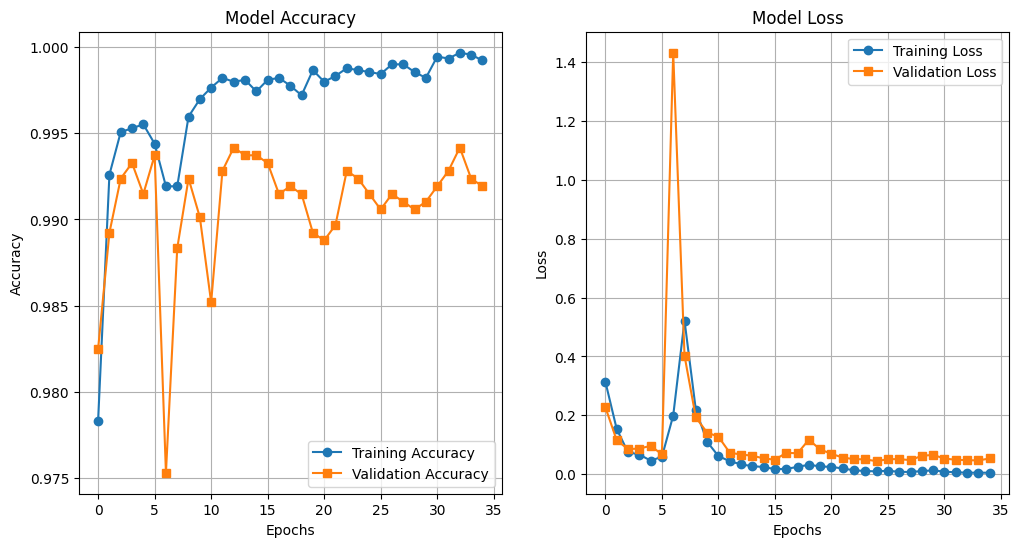

In [21]:
import matplotlib.pyplot as plt

# Plot Accuracy Curves
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(history_fusion.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(history_fusion.history['val_accuracy'], label='Validation Accuracy', marker='s')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plot Loss Curves
plt.subplot(1, 2, 2)
plt.plot(history_fusion.history['loss'], label='Training Loss', marker='o')
plt.plot(history_fusion.history['val_loss'], label='Validation Loss', marker='s')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

# **classification model (Dense Neural Network)**

In [22]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, accuracy_score

# Define Early Stopping and Learning Rate Scheduler
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
lr_scheduler = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)

# Concatenate SBM and MSTM Features
X_train_fusion = np.concatenate([X_train_sbm, X_train_mstm], axis=1)
X_test_fusion = np.concatenate([X_test_sbm, X_test_mstm], axis=1)

print("Fused Training Features Shape:", X_train_fusion.shape)
print("Fused Testing Features Shape:", X_test_fusion.shape)

# Number of Classes
num_classes = y_train.shape[1]

# Define DNN Classification Model
def build_dnn_classification_model(input_dim, num_classes):
    inputs = layers.Input(shape=(input_dim,), name='Fusion_Input')

    # Fully Connected Layers with Batch Normalization
    x = layers.Dense(128, activation='relu', name="Dense_1")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Dense(64, activation='relu', name="Dense_2")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)

    # Output Layer
    outputs = layers.Dense(num_classes, activation='softmax', name="Classification_Output")(x)

    # Model Compilation
    model = models.Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer=optimizers.Adam(learning_rate=0.001),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# Create and Compile the DNN Model
dnn_model = build_dnn_classification_model(X_train_fusion.shape[1], num_classes)
dnn_model.summary()

# Train the Model
history_dnn = dnn_model.fit(
    X_train_fusion, y_train,
    validation_data=(X_test_fusion, y_test),
    epochs=50,
    batch_size=32,
    callbacks=[early_stop, lr_scheduler]
)

# Evaluate Model Performance
y_pred_dnn = dnn_model.predict(X_test_fusion)
y_pred_classes_dnn = y_pred_dnn.argmax(axis=1)
y_true = y_test.argmax(axis=1)

# Print Accuracy and Classification Report
print("DNN Fusion Model Accuracy:", accuracy_score(y_true, y_pred_classes_dnn))
print(classification_report(y_true, y_pred_classes_dnn, digits=4))


Fused Training Features Shape: (8910, 256)
Fused Testing Features Shape: (2228, 256)


Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Fusion_Input (InputLayer)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Classification_Output (Dense)   │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,310 (165.27 KB)

 Trainable params: 41,926 (163.77 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.9209 - loss: 0.2695 - val_accuracy: 0.9906 - val_loss: 0.0294 - learning_rate: 0.0010
Epoch 2/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9921 - loss: 0.0274 - val_accuracy: 0.9910 - val_loss: 0.0219 - learning_rate: 0.0010
Epoch 3/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9916 - loss: 0.0294 - val_accuracy: 0.9910 - val_loss: 0.0259 - learning_rate: 0.0010
Epoch 4/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9956 - loss: 0.0190 - val_accuracy: 0.9906 - val_loss: 0.0232 - learning_rate: 0.0010
Epoch 5/50
272/279 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9952 - loss: 0.0174
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
279/279 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9952 - loss: 0.0174 - val_accuracy: 0.9915 - val_loss: 0.0294 - learning_rate: 0.0010
Epoch 6/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9953 - loss: 0.0183 

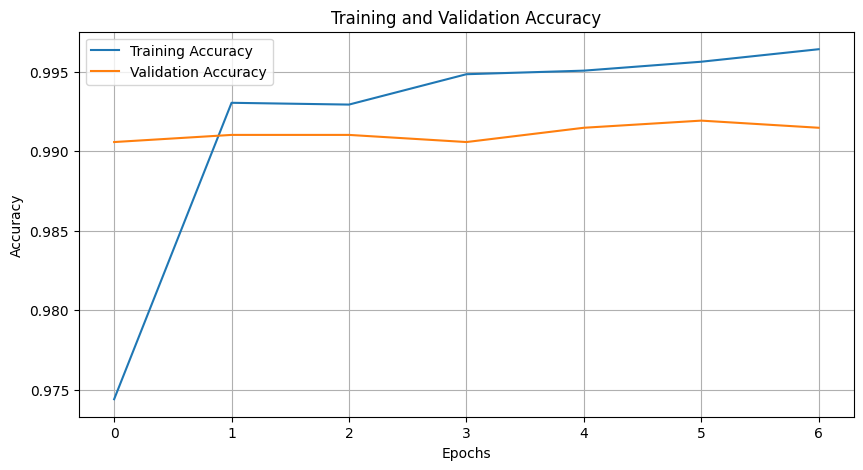

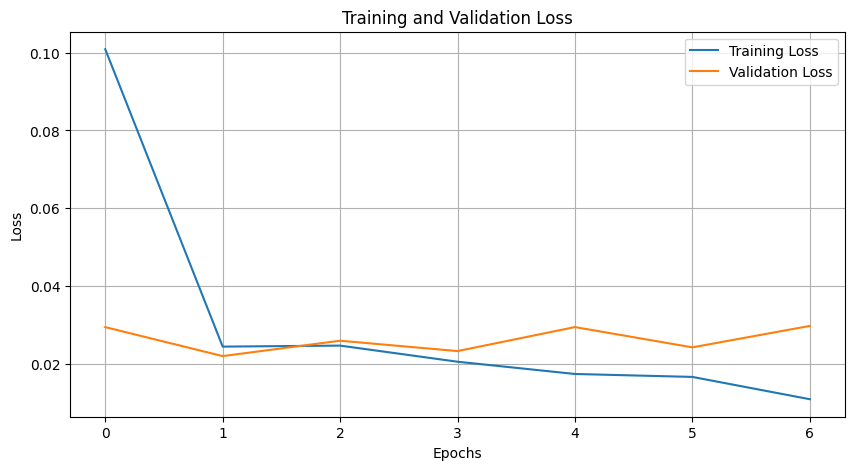

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Plot Accuracy
plt.figure(figsize=(10, 5))
plt.plot(history_dnn.history['accuracy'], label='Training Accuracy')
plt.plot(history_dnn.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Plot Loss
plt.figure(figsize=(10, 5))
plt.plot(history_dnn.history['loss'], label='Training Loss')
plt.plot(history_dnn.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()


70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


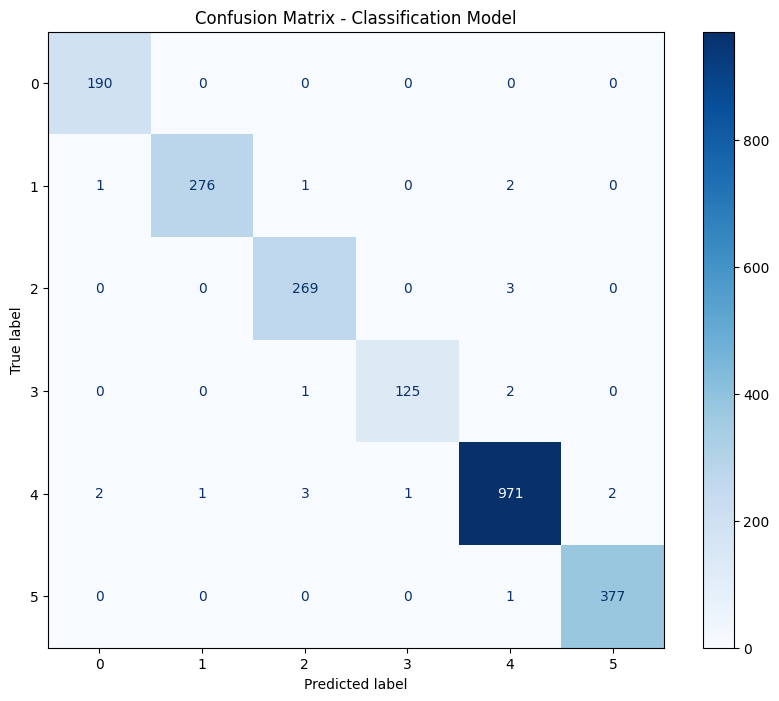

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

# Get Predictions
y_pred = dnn_model.predict(X_test_fusion) # Changed classification_model to dnn_model
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred_classes)

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(10, 8))
cm_display = ConfusionMatrixDisplay(confusion_matrix=conf_matrix)
cm_display.plot(ax=ax, cmap='Blues')
plt.title('Confusion Matrix - Classification Model')
plt.show()

# **Plot results**

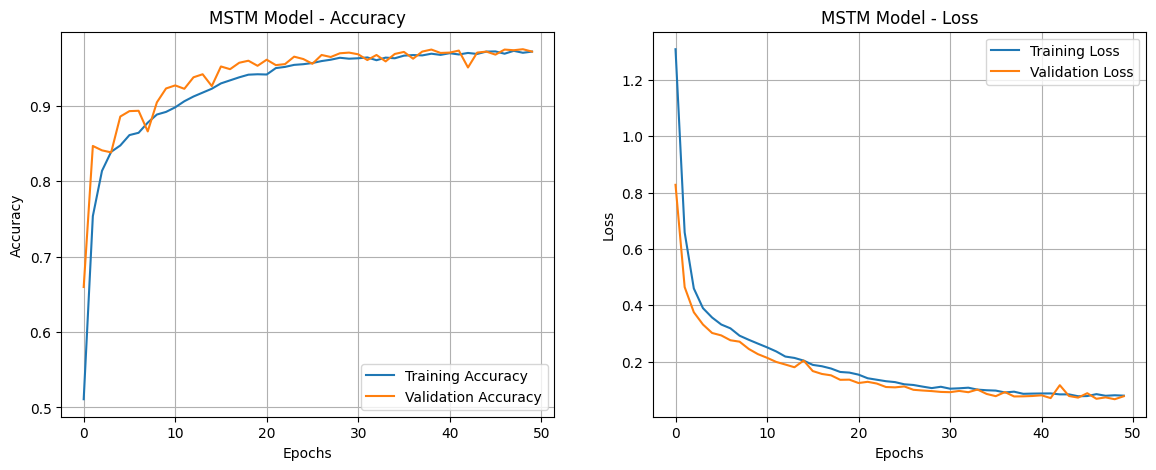

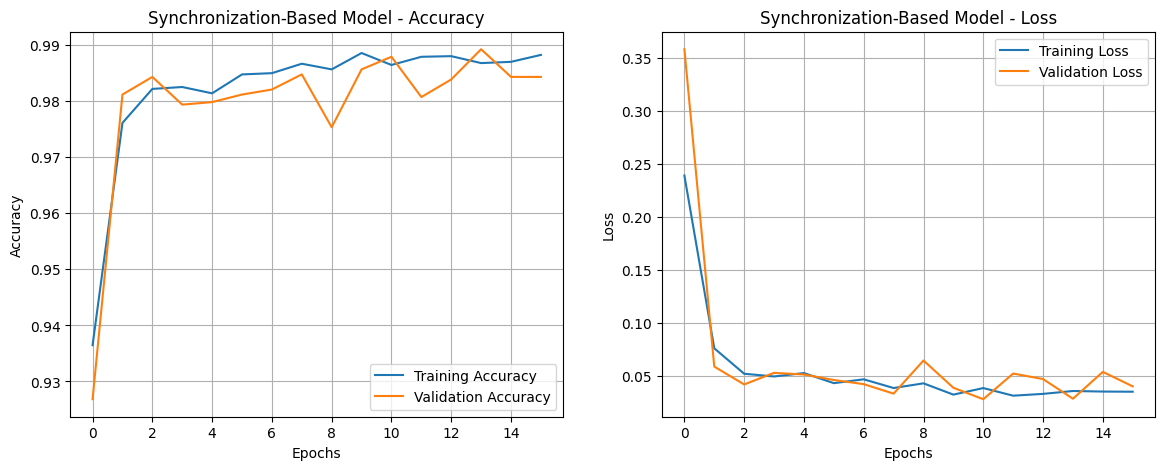

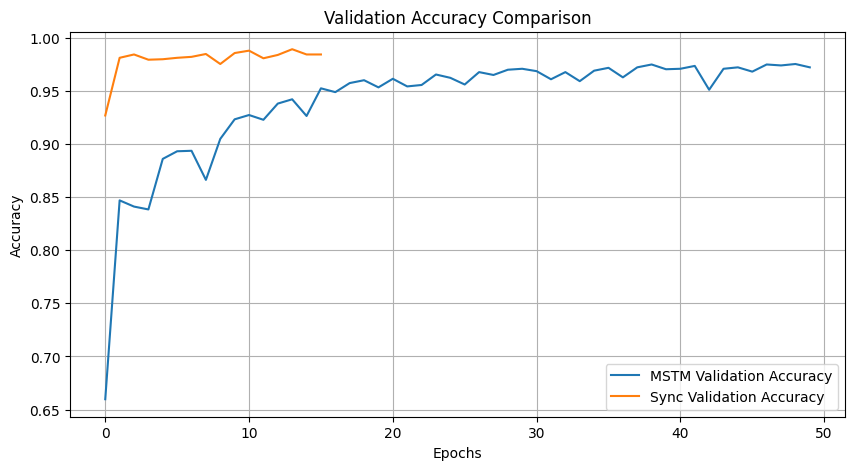

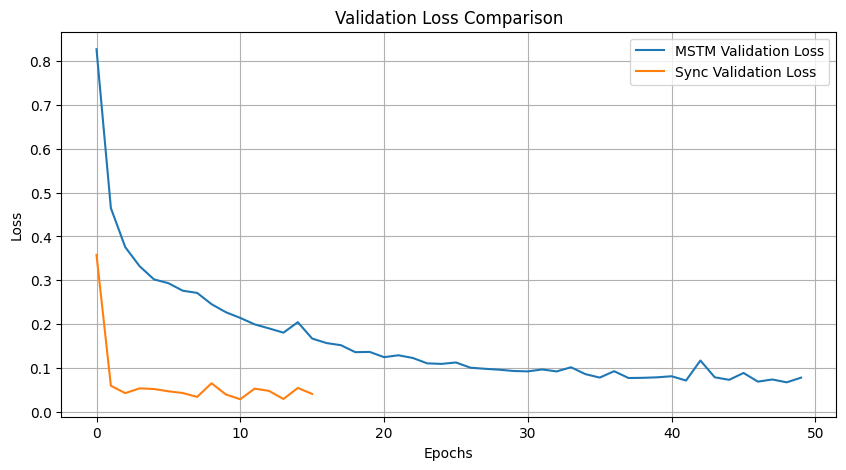

In [25]:
import matplotlib.pyplot as plt

# Function to plot training history
def plot_history(history, title):
    # Plot Accuracy
    plt.figure(figsize=(14, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title(f'{title} - Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f'{title} - Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    plt.show()

# Plot for MSTM Model
# Changed history_mstm to history
plot_history(history, "MSTM Model")

# Plot for Synchronization-Based Model
plot_history(history_sync, "Synchronization-Based Model")

# Comparison of Accuracy
plt.figure(figsize=(10, 5))
# Changed history_mstm to history
plt.plot(history.history['val_accuracy'], label='MSTM Validation Accuracy')
plt.plot(history_sync.history['val_accuracy'], label='Sync Validation Accuracy')
plt.title('Validation Accuracy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Comparison of Loss
plt.figure(figsize=(10, 5))
# Changed history_mstm to history
plt.plot(history.history['val_loss'], label='MSTM Validation Loss')
plt.plot(history_sync.history['val_loss'], label='Sync Validation Loss')
plt.title('Validation Loss Comparison')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# **visualizing the dataset**

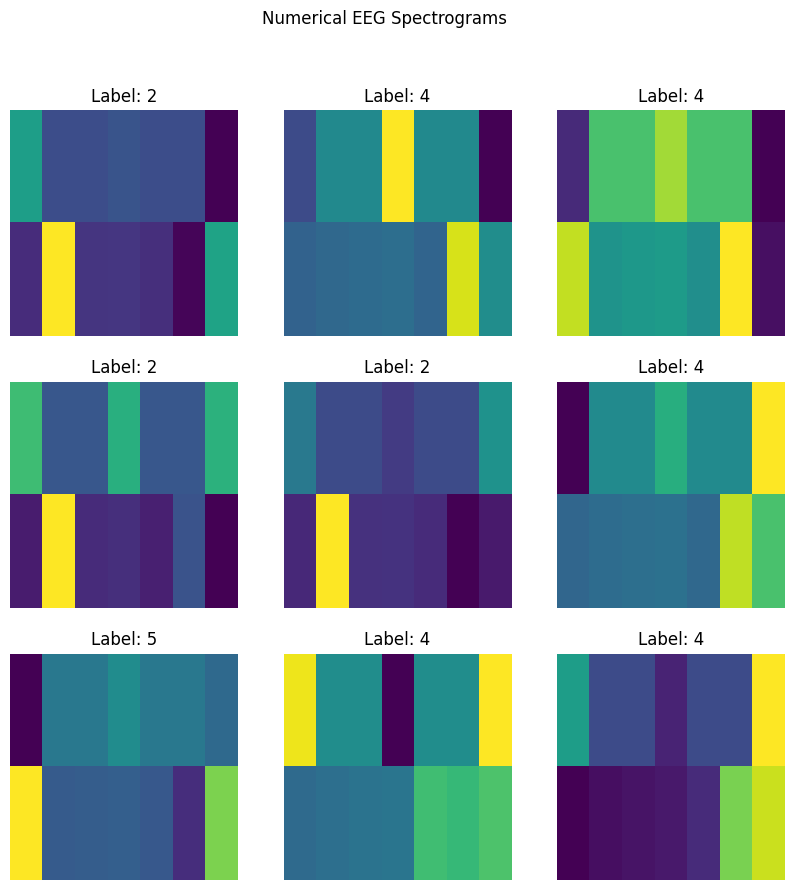

In [26]:
# Example with 2 rows and 7 columns (adjust as needed)
plt.figure(figsize=(10, 10))
num_samples = 9
for i in range(num_samples):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[i].reshape(2, 7), cmap='viridis', aspect='auto')
    plt.title(f"Label: {np.argmax(y_train[i])}")
    plt.axis('off')

plt.suptitle('Numerical EEG Spectrograms')
plt.show()

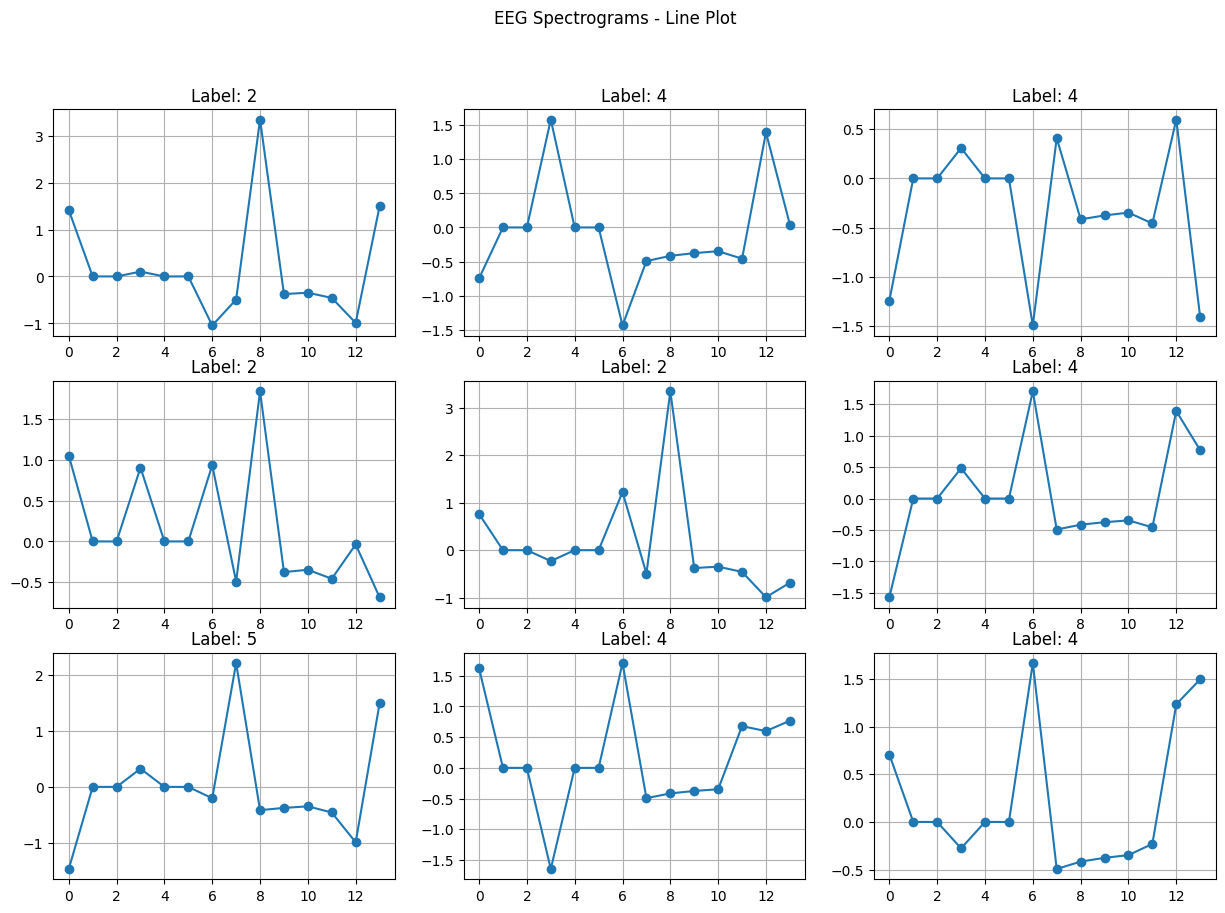

In [27]:
import matplotlib.pyplot as plt

# Display first 9 samples as line plots
plt.figure(figsize=(15, 10))
num_samples = 9
for i in range(num_samples):
    plt.subplot(3, 3, i + 1)
    plt.plot(X_train[i], marker='o')  # Plot each feature as a point on the line
    plt.title(f"Label: {np.argmax(y_train[i])}")
    plt.grid(True)

plt.suptitle('EEG Spectrograms - Line Plot')
plt.show()


In [28]:
import psutil
ram_gb = psutil.virtual_memory().total / 1e+9
print(f"Total RAM: {ram_gb:.2f} GB")

Total RAM: 13.61 GB


In [29]:
import shutil

total, used, free = shutil.disk_usage('/')
total_gb = total / (2**30)
print(f"Total Disk Space: {total_gb:.2f} GB")

Total Disk Space: 107.72 GB
